In [1]:
# تثبيت المكتبات المطلوبة للمعالجة والذكاء الاصطناعي والمطابقة
!pip install opencv-python pillow matplotlib rapidfuzz requests


[notice] A new release of pip is available: 24.3.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


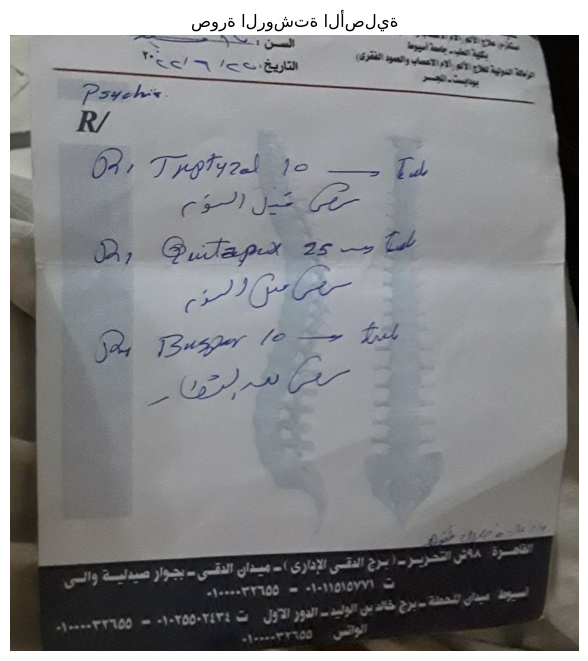

In [2]:
import cv2
import matplotlib.pyplot as plt


image_path = "p_y.jpg"  # استبدليها باسم صورتك

# قراءة الصورة
img = cv2.imread(image_path)

# OpenCV بيقرا الصور BGR، فنحولها لـ RGB عشان تظهر بالألوان الصح في Matplotlib
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)



# عرض الصورة جوه الـ Notebook
plt.figure(figsize=(8, 8))
plt.imshow(img_rgb)
plt.axis("off")
plt.title("صورة الروشتة الأصلية")
plt.show()

In [3]:
!pip install google-genai


[notice] A new release of pip is available: 24.3.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import re
import json

In [5]:
import getpass, PIL.Image
from google import genai
from google.genai import types

client = genai.Client(api_key=getpass.getpass("API key: "), http_options=types.HttpOptions(timeout=60000))
img = PIL.Image.open("p_y.jpg")
img.thumbnail((1600, 1600))

In [6]:
import json, time

prompt = """اقرأ الروشتة دي واستخرج الأدوية المكتوبة. ارجع JSON فقط، قايمة، وكل دواء فيها: name (الاسم التجاري بحروف إنجليزي بس من غير جرعة) و strength_mg (رقم الجرعة بس، أو null لو مش مكتوب). لو الاسم مش واضح اكتب اللي شايفه بالظبط ومتخمنش اسم دواء."""

models_to_try = ["gemini-3.5-flash", "gemini-3.8-flash", "gemini-3.7-flash", "gemini-3.5-flash-lite", "gemini-3.1-flash-lite", "gemini-flash-latest"]
drugs = None

for round_no in range(1, 4):
    for m in models_to_try:
        try:
            response = client.models.generate_content(model=m, contents=[img, prompt], config={"response_mime_type": "application/json"})
            drugs = json.loads(response.text)
            print("اشتغل مع:", m)
            break
        except Exception as e:
            print(m, "فشل:", str(e)[:50])
    if drugs is not None:
        break
    print("الجولة", round_no, "فشلت، هستنى 30 ثانية")
    time.sleep(30)

print(drugs)

Direct use of automatic function calling (AFC) in Models.generate_content is not recommended. Instead, we recommend to use AFC in Chat.send_message. Similarly, direct use of AFC in Models.generate_content_stream is not recommended. Instead, we recommend to use AFC in Chat.send_message_stream.


اشتغل مع: gemini-3.5-flash
[{'name': 'Tryptizol', 'strength_mg': 10}, {'name': 'Quitapex', 'strength_mg': 25}, {'name': 'Buspar', 'strength_mg': 10}]


In [7]:

import pandas as pd
from rapidfuzz import process, fuzz

df_drugs = pd.read_csv('eg_drugs.csv')

In [8]:
print(df_drugs.shape)
print(list(df_drugs.columns))

(26562, 25)
['id', 'name', 'arabic', 'active', 'company', 'price', 'oldprice', 'availability', 'barcode', 'slug', 'units', 'description', 'uses', 'matched_fda_ingredients', 'uses_summary', 'uses_summary_en', 'warning_high_blood_pressure', 'warning_diabetes', 'warning_pregnancy', 'warning_lactation', 'warning_kidney', 'warning_liver', 'warning_heart', 'warnings_summary', 'warnings_summary_en']


In [9]:
import re
from rapidfuzz import process, fuzz

df_drugs['brand'] = df_drugs['name'].fillna('').str.lower().apply(lambda x: re.split(r'\d', x)[0].strip())
brands = df_drugs['brand'].unique().tolist()

def check_name(drug_name):
    best, score, _ = process.extractOne(drug_name.lower(), brands, scorer=fuzz.ratio)
    return best, score

for test in ["Tryptizol", "Quitapex", "Buspar", "NotRealDrug"]:
    print(test, "->", check_name(test))

Tryptizol -> ('tryptizol', 100.0)
Quitapex -> ('quitapex', 100.0)
Buspar -> ('buspar', 100.0)
NotRealDrug -> ('normesar', 63.1578947368421)


In [10]:
def available_strengths(brand):
    rows = df_drugs[df_drugs['brand'] == brand]['name']
    return sorted(set(re.findall(r'(\d+(?:\.\d+)?)\s*mg', ' '.join(rows))))

for b in ["tryptizol", "quitapex", "buspar"]:
    print(b, "->", available_strengths(b))

tryptizol -> ['10', '25']
quitapex -> ['100', '150', '200', '25', '300', '400', '50']
buspar -> ['10', '15']


In [11]:
THRESHOLD = 70

def check_drug(name, strength):
    brand, score = check_name(name)
    if score < THRESHOLD:
        return "غير مسجل", None, []
    options = available_strengths(brand)
    if str(strength) in options:
        return "موجود في قاعدة الأدوية", brand, options
    return "جرعة مختلفة", brand, options

tests = [("Tryptizol", 10), ("Quitapex", 25), ("Buspar", 10), ("Buspar", 20), ("NotRealDrug", 50)]
for n, s in tests:
    print(n, s, "->", check_drug(n, s))

Tryptizol 10 -> ('موجود في قاعدة الأدوية', 'tryptizol', ['10', '25'])
Quitapex 25 -> ('موجود في قاعدة الأدوية', 'quitapex', ['100', '150', '200', '25', '300', '400', '50'])
Buspar 10 -> ('موجود في قاعدة الأدوية', 'buspar', ['10', '15'])
Buspar 20 -> ('جرعة مختلفة', 'buspar', ['10', '15'])
NotRealDrug 50 -> ('غير مسجل', None, [])


In [12]:
rows = []
for d in drugs:
    nums = re.findall(r'\d+(?:\.\d+)?', str(d.get('strength_mg') or ''))
    strength = nums[0] if nums else None
    status, brand, options = check_drug(d['name'], strength)
    if strength is None and status != "غير مسجل":
        status = "الجرعة غير مقروءة"
    rows.append({"من Gemini": d['name'], "الجرعة": strength, "الحالة": status, "المتاح في الداتابيز": options})

print(pd.DataFrame(rows).to_string(index=False))

من Gemini الجرعة                 الحالة               المتاح في الداتابيز
Tryptizol     10 موجود في قاعدة الأدوية                          [10, 25]
 Quitapex     25 موجود في قاعدة الأدوية [100, 150, 200, 25, 300, 400, 50]
   Buspar     10 موجود في قاعدة الأدوية                          [10, 15]
